<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How much of a team score do returned player rows explain?

A box-score query can return valid rows without covering the whole team. We will join player and team totals for one fixed men’s basketball game, check the scoring arithmetic, and separate a deliberate minutes filter from points that no returned player row explains.

The default uses an **existing trimmed test fixture** from this worker’s repository. It retains four players per team while preserving reported team totals. It is explicitly incomplete, not a complete historical roster or a newly captured response. The original capture time was not recorded. The real worker fetches this fixture over loopback HTTP and parses it through its normal code. A separate live mode queries ESPN for the same event; it never falls back to replay. [Setup and provenance](README.md).

## Choose a minutes cutoff

`MIN_MINUTES` is an inclusive threshold in reported whole minutes, from 0 through 60. A player qualifies only if minutes are known, the player is not marked did-not-play, and minutes meet the threshold. The default 0 includes every eligible returned row; the experiment changes only this to 20. `DATA_MODE` is replay or live. The game is fixed to ESPN event **401920686**; changing modes does not silently change games. Restart and run all after editing.

In [1]:
DATA_MODE = "replay"  # "live" calls public ESPN for the same fixed event.
MIN_MINUTES = 0  # Inclusive reported minutes; experiment: 20.

In [2]:
import haybarn
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

server, thread, previous, run_utc = configure(DATA_MODE, MIN_MINUTES)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 30
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-ncaa-basketball/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-ncaa-basketball/notebooks/pyproject.toml.

In [3]:
source_label = (
    "Trimmed repository replay fixture; capture time unavailable"
    if DATA_MODE == "replay"
    else "Live ESPN response for fixed historical event; no replay fallback"
)
prose(
    f"**Source mode: {DATA_MODE}.** {source_label}. Run started **{run_utc}**. "
    "Event 401920686 is identified in the fixture as Wagner at UConn, 2026-11-10 00:00 UTC. "
    "The replay is a retained subset; live row coverage may differ. "
    "Separate worker calls are not an atomic snapshot."
)

**Source mode: replay.** Trimmed repository replay fixture; capture time unavailable. Run started **2026-11-14T09:00:22.050176+00:00**. Event 401920686 is identified in the fixture as Wagner at UConn, 2026-11-10 00:00 UTC. The replay is a retained subset; live row coverage may differ. Separate worker calls are not an atomic snapshot.

## Attach the unchanged public worker

The literal command fetches an immutable public Git revision and runs the packaged entry point with pinned SDK, RPC, Arrow and HTTP client versions. All four supported upstream URL overrides are explicitly set to loopback in replay and cleared in live mode. The helper restores the caller’s environment at cleanup. SQL below materializes both worker calls before any DataFrame capture.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ncaa_basketball' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-ncaa-basketball@a3be7c2dd5860c5540e326bc365d1fe816840196 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==25.0.1 --with httpx==0.28.1 vgi-ncaa-basketball');
CREATE TABLE settings AS SELECT {{ MIN_MINUTES }}::INTEGER AS minimum_minutes;
CREATE TABLE player_rows AS SELECT * FROM ncaa_basketball.mens.box_score(401920686);
CREATE TABLE team_rows AS SELECT * FROM ncaa_basketball.mens.team_box_score(401920686);
SELECT team_id,team_name,points AS reported_team_points FROM team_rows ORDER BY team_id;

Running query in 'DuckDBPyConnection'

1 rows affected.

8 rows affected.

2 rows affected.

,team_id,team_name,reported_team_points
0,41,UConn Huskies,83
1,2681,Wagner Seahawks,41


## Audit the rows before filtering

Use `(event_id, team_id, player_id)` as the player key and `(event_id, team_id)` as the team join key. Missing points remain unknown and are counted separately. Did-not-play rows are retained for diagnostics; their missing stats are not converted into zero-performance players. Scoring arithmetic is **2 × field goals made + three-pointers made + free throws made**, because field-goal counts already include threes.

In [5]:
%%sql
CREATE TABLE evaluated AS
SELECT p.*,t.team_name,t.points AS reported_team_points,
       2*p.field_goals_made+p.three_pointers_made+p.free_throws_made AS reconstructed_points,
       p.minutes IS NOT NULL AND NOT coalesce(p.did_not_play,false)
           AND p.minutes >= s.minimum_minutes AS selected
FROM player_rows p JOIN team_rows t USING(event_id,team_id) CROSS JOIN settings s;
SELECT team_name,count(*) AS returned_players,count(*) FILTER(WHERE did_not_play) AS did_not_play,
       count(*) FILTER(WHERE points IS NULL) AS unknown_points,
       count(*) FILTER(WHERE minutes IS NULL AND NOT coalesce(did_not_play,false)) AS unknown_minutes,
       sum(points) AS points_in_returned_rows,max(reported_team_points) AS reported_team_points
FROM evaluated GROUP BY team_name ORDER BY team_name;

Running query in 'DuckDBPyConnection'

8 rows affected.

,team_name,returned_players,did_not_play,unknown_points,unknown_minutes,points_in_returned_rows,reported_team_points
0,UConn Huskies,4,0,0,0,43.0,83
1,Wagner Seahawks,4,0,0,0,23.0,41


## Decompose the reported team score

The green segment is known points from qualifying returned players. The middle segment is known points from other returned players. The residual is **reported team points minus all known returned-player points**: it can reflect omitted rows or unknown values and must not be assigned to invented players. No join drops a reported team. If player detail exceeds the reported total, the reconciliation check fails rather than clipping that discrepancy away. A zero team total has an unavailable percentage denominator.

In [6]:
%%sql
CREATE TABLE coverage AS
SELECT t.event_id,t.team_id,t.team_name,t.points AS team_points,
       count(e.player_id) AS returned_players,
       count(e.player_id) FILTER(WHERE e.selected) AS selected_players,
       count(e.player_id) FILTER(WHERE e.points IS NULL) AS unknown_point_rows,
       coalesce(sum(e.points),0) AS known_returned_points,
       coalesce(sum(e.points) FILTER(WHERE e.selected),0) AS selected_points,
       coalesce(sum(e.points) FILTER(WHERE NOT e.selected),0) AS other_returned_points,
       t.points-coalesce(sum(e.points),0) AS unattributed_points,
       100.0*coalesce(sum(e.points) FILTER(WHERE e.selected),0)/nullif(t.points,0) AS selected_percent
FROM team_rows t LEFT JOIN evaluated e USING(event_id,team_id)
GROUP BY t.event_id,t.team_id,t.team_name,t.points;
SELECT team_name,returned_players,selected_players,selected_points,other_returned_points,
       unattributed_points,team_points,round(selected_percent,2) AS selected_percent
FROM coverage ORDER BY team_name;

Running query in 'DuckDBPyConnection'

2 rows affected.

,team_name,returned_players,selected_players,selected_points,other_returned_points,unattributed_points,team_points,selected_percent
0,UConn Huskies,4,4,43.0,0.0,40.0,83,51.81
1,Wagner Seahawks,4,4,23.0,0.0,18.0,41,56.10


In [7]:
%%sql coverage_frame <<
SELECT * FROM coverage ORDER BY team_name;

Running query in 'DuckDBPyConnection'

In [8]:
unattributed = int(coverage_frame.unattributed_points.sum())
selected = int(coverage_frame.selected_points.sum())
count = int(coverage_frame.selected_players.sum())
prose(
    f"At **{MIN_MINUTES} reported minutes or more**, **{count} returned players** account for "
    f"**{selected} known points**. Another **{unattributed} reported points** "
    "are not explained by any known returned-player score. "
    + (
        "This is expected for the deliberately trimmed replay fixture. "
        if DATA_MODE == "replay"
        else "This residual is measured from the live response, not assumed to be zero. "
    )
    + "Changing the cutoff redistributes known returned points between selected and other rows; "
    "it cannot repair missing row coverage."
)

At **0 reported minutes or more**, **8 returned players** account for **66 known points**. Another **58 reported points** are not explained by any known returned-player score. This is expected for the deliberately trimmed replay fixture. Changing the cutoff redistributes known returned points between selected and other rows; it cannot repair missing row coverage.

findfont: Failed to find font weight semibold for Arial, now using 700.


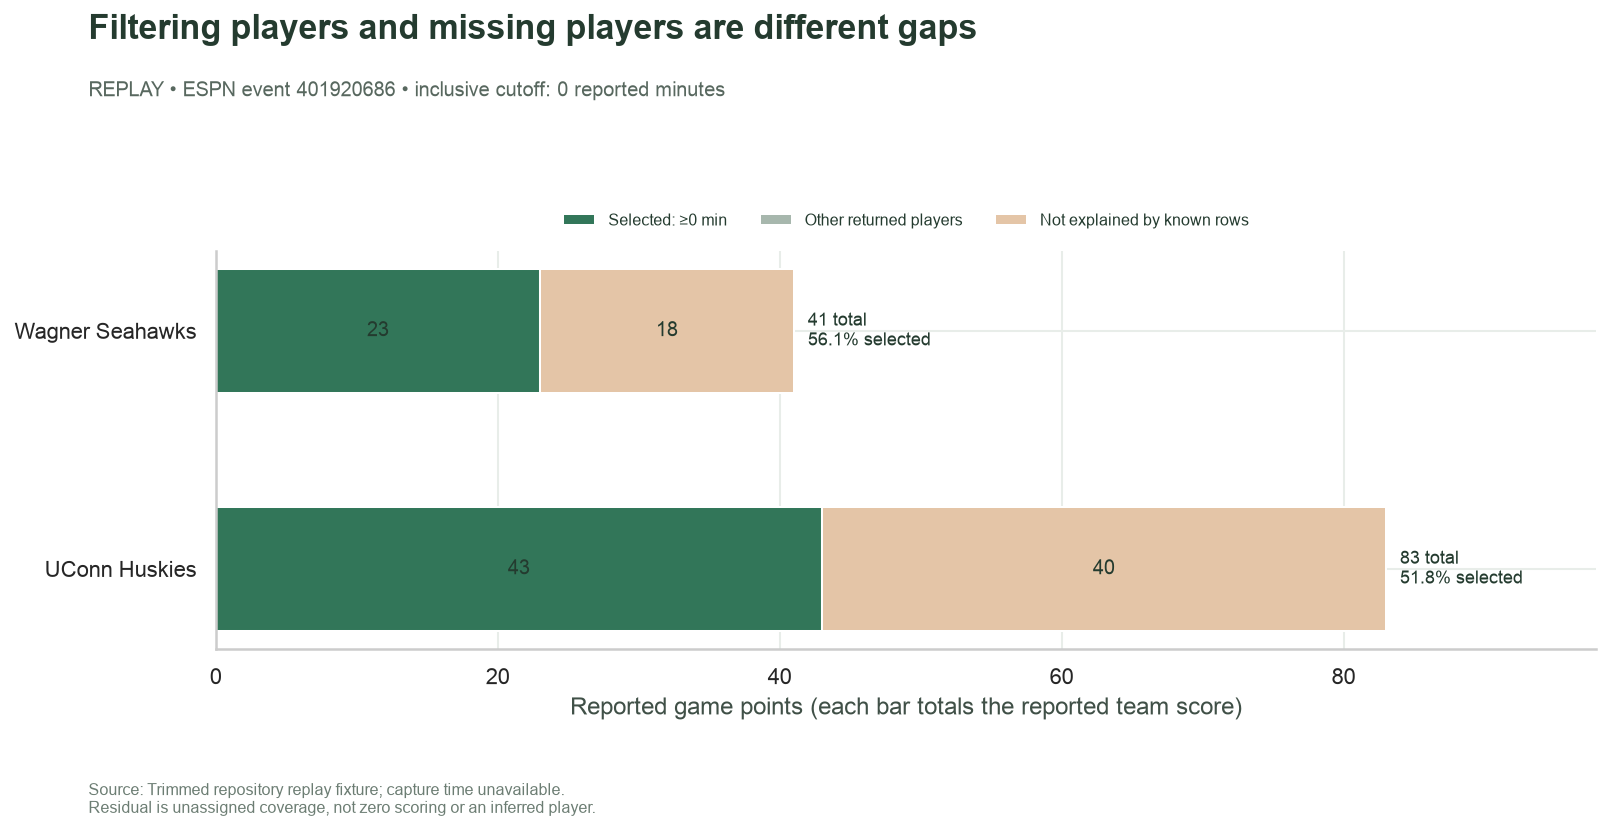

In [9]:
fig, ax = plt.subplots(figsize=(11.5, 5.8))
left = [0] * len(coverage_frame)
for column, color, label in [
    ("selected_points", "#327659", f"Selected: ≥{MIN_MINUTES} min"),
    ("other_returned_points", "#A7B7AD", "Other returned players"),
    ("unattributed_points", "#E4C5A7", "Not explained by known rows"),
]:
    bars = ax.barh(
        coverage_frame.team_name, coverage_frame[column], left=left, color=color, label=label, height=0.52
    )
    ax.bar_label(
        bars,
        labels=[str(int(v)) if v > 0 else "" for v in coverage_frame[column]],
        label_type="center",
        fontsize=10,
    )
    left = [a + b for a, b in zip(left, coverage_frame[column], strict=False)]
ax.set_xlabel("Reported game points (each bar totals the reported team score)")
ax.set_xlim(0, max(coverage_frame.team_points) * 1.18)
for i, item in enumerate(coverage_frame.itertuples()):
    percent = "unavailable" if item.team_points == 0 else f"{item.selected_percent:.1f}% selected"
    ax.text(item.team_points + 1, i, f"{item.team_points:.0f} total\n{percent}", va="center", fontsize=9)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=3, fontsize=8)
chart(
    fig,
    "Filtering players and missing players are different gaps",
    f"{DATA_MODE.upper()} • ESPN event 401920686 • inclusive cutoff: {MIN_MINUTES} reported minutes",
    "Source: " + source_label + ".\nResidual is unassigned coverage, not zero scoring or an inferred player.",
)

## Inspect the retained player detail

The second chart shows known player scores, sorted within each team. Minutes and eligibility remain visible next to each name. Gray bars are real returned rows excluded by the cutoff, not missing players. Rows with unknown points are listed in the diagnostics and omitted from this points chart; did-not-play is not plotted as a fabricated zero.

In [10]:
%%sql player_frame <<
SELECT team_name,player_name,player_id,minutes,points,selected,reconstructed_points
FROM evaluated WHERE points IS NOT NULL ORDER BY team_name,points DESC,player_id;

Running query in 'DuckDBPyConnection'

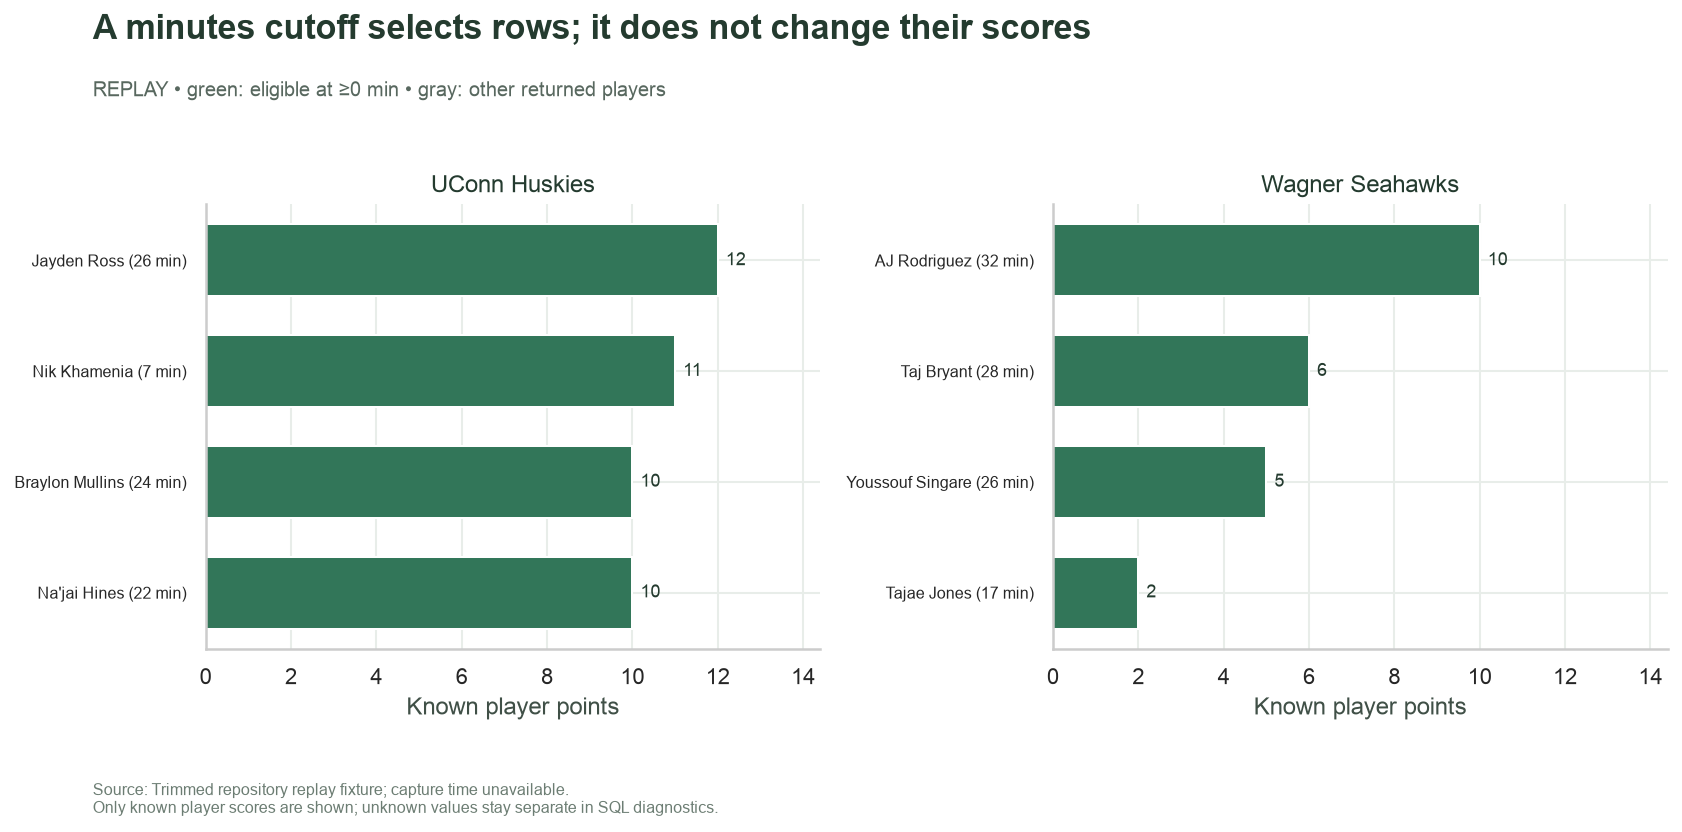

In [11]:
fig, axes = plt.subplots(
    1, len(coverage_frame), figsize=(12, max(5.8, len(player_frame) * 0.22)), squeeze=False
)
for ax, team in zip(axes[0], coverage_frame.team_name, strict=False):
    subset = player_frame[player_frame.team_name == team].reset_index(drop=True)
    if subset.empty:
        ax.text(0.5, 0.5, "No known player points", transform=ax.transAxes, ha="center")
        ax.set_title(team)
        continue
    bars = ax.barh(
        range(len(subset)),
        subset.points,
        color=["#327659" if v else "#A7B7AD" for v in subset.selected],
        height=0.65,
    )
    ax.bar_label(bars, padding=4, fontsize=9)
    names = [
        f"{r.player_name} ({'?' if pd.isna(r.minutes) else int(r.minutes)} min)" for r in subset.itertuples()
    ]
    ax.set_yticks(range(len(subset)), names, fontsize=8)
    ax.invert_yaxis()
    ax.set(xlabel="Known player points", title=team, xlim=(0, max(1, player_frame.points.max()) * 1.2))
chart(
    fig,
    "A minutes cutoff selects rows; it does not change their scores",
    f"{DATA_MODE.upper()} • green: eligible at ≥{MIN_MINUTES} min • gray: other returned players",
    "Source: "
    + source_label
    + ".\nOnly known player scores are shown; unknown values stay separate in SQL diagnostics.",
)

## Reconcile the arithmetic and coverage

Check the same relationships in replay and live mode without assuming identical roster size or totals. Known shooting counts must reconstruct known player points; selected points cannot exceed known returned points; the three score components must sum back to the reported team score. The replay audit additionally confirms that every request stayed on the one recorded endpoint.

In [12]:
%%sql checks <<
SELECT 'Exactly two teams for the fixed game' AS check_name,count(*)=2 AND count(DISTINCT team_id)=2 AS passed FROM team_rows
UNION ALL SELECT 'Player keys are unique',count(*)=count(DISTINCT (event_id,team_id,player_id)) FROM player_rows
UNION ALL SELECT 'Team join preserves every player row',(SELECT count(*) FROM evaluated)=(SELECT count(*) FROM player_rows)
UNION ALL SELECT 'Known scoring arithmetic agrees',coalesce(bool_and(points=reconstructed_points) FILTER(WHERE points IS NOT NULL AND reconstructed_points IS NOT NULL),false) FROM evaluated
UNION ALL SELECT 'Known values are nonnegative',bool_and(points IS NULL OR points>=0) AND bool_and(minutes IS NULL OR minutes>=0) FROM evaluated
UNION ALL SELECT 'Every selected player meets the minutes rule',coalesce(bool_and(minutes>=(SELECT minimum_minutes FROM settings) AND NOT coalesce(did_not_play,false)) FILTER(WHERE selected),true) FROM evaluated
UNION ALL SELECT 'No team points are silently dropped',count(*)=(SELECT count(*) FROM team_rows) FROM coverage
UNION ALL SELECT 'Known coverage does not exceed team totals',bool_and(known_returned_points<=team_points AND unattributed_points>=0) FROM coverage
UNION ALL SELECT 'Selected known points are bounded',bool_and(selected_points>=0 AND selected_points<=known_returned_points) FROM coverage
UNION ALL SELECT 'Components reconcile to reported scores',bool_and(selected_points+other_returned_points+unattributed_points=team_points) FROM coverage
ORDER BY check_name;

Running query in 'DuckDBPyConnection'

In [13]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
if server:
    assert server.requests and all(
        request == "/apis/site/v2/sports/basketball/mens-college-basketball/summary?event=401920686"
        for request in server.requests
    )
    prose(
        f"**{len(checks)} SQL checks passed.** Replay served {len(server.requests)} HTTP request(s), "
        "all for the single recorded summary endpoint; no external data fallback exists."
    )
else:
    prose(
        f"**{len(checks)} SQL checks passed.** Live ESPN results were used directly; "
        "replay server was not started."
    )

,check_name,passed
0,Components reconcile to reported scores,True
1,Every selected player meets the minutes rule,True
2,Exactly two teams for the fixed game,True
3,Known coverage does not exceed team totals,True
4,Known scoring arithmetic agrees,True
5,Known values are nonnegative,True
6,No team points are silently dropped,True
7,Player keys are unique,True
8,Selected known points are bounded,True
9,Team join preserves every player row,True


**10 SQL checks passed.** Replay served 1 HTTP request(s), all for the single recorded summary endpoint; no external data fallback exists.

## Focused experiment: require 20 reported minutes

Change only `MIN_MINUTES` from **0** to **20**, restart and run all. Predict fewer eligible rows, with some green points moving to gray. The unassigned residual should stay unchanged because it is calculated before the cutoff. Compare both chart colors, the selected-player count and selected percentage.

This is a selection experiment, not a measure of player efficiency or causal impact. Whole-minute reporting, omitted players and a single game limit the interpretation. Reset to **0**. Use the README’s separate output command to preserve the saved default. Switching `DATA_MODE` to live is a separate source-validation exercise, not the one-parameter cutoff experiment.

In [14]:
connection.close()
cleanup(server, thread, previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>